# 02_Data_Preprocessing: Làm sạch, khôi phục cầu bị che khuất, feature engineering, chia tập

**Phục vụ:** Chương 3, mục 3.3–3.5 của báo cáo. **Đầu vào:** `data/daily.parquet` từ notebook 01.

| Bước | Nội dung | Mục báo cáo |
|---|---|---|
| 1 | Nạp dữ liệu, kiểm tra bất thường | 3.3 |
| 2 | **Khôi phục cầu bị che khuất** khi hết hàng (dùng profile doanh số theo giờ) | 3.3 |
| 3 | Tạo target `y` và loại ngày hết hàng nặng | 3.3 |
| 4 | Feature engineering (không rò rỉ thông tin tương lai) | 3.4 |
| 5 | Chia tập theo thời gian 70 / 15 / 15 | 3.5 |
| 6 | Lưu `features.parquet` + `feature_meta.json` cho notebook 03 | |

**Ý tưởng khôi phục cầu:** nếu một sản phẩm hết hàng từ 18h, doanh số quan sát chỉ phản ánh phần cầu của các giờ còn hàng. Gọi `avail_share` là tỷ trọng doanh số thường rơi vào các giờ còn hàng (theo profile giờ của ngành hàng). Cầu ước lượng = doanh số quan sát / `avail_share`.

In [1]:
!pip install -q -U datasets

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from datasets import load_dataset

# ---- Cấu hình ----
USE_DRIVE = True
PROJECT = "Dynamic_Pricing_Project"
RANDOM_STATE = 42
MIN_AVAIL = 0.5          # avail_share < 0.5 → hết hàng nặng: không dùng làm target
PROFILE_SAMPLE = 200_000 # số dòng dùng để ước lượng profile theo giờ
SPLIT = (0.70, 0.15, 0.15)

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = Path("/content/drive/MyDrive") / PROJECT
    except ImportError:
        OUT_DIR = Path(PROJECT)
else:
    OUT_DIR = Path(PROJECT)
for sub in ["data", "figures", "tables"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e4df", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT_DIR / "figures" / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()

LOG = {}  # nhật ký tiền xử lý, lưu ra JSON

Mounted at /content/drive


## 1. Nạp dữ liệu và kiểm tra bất thường

In [3]:
df = pd.read_parquet(OUT_DIR / "data" / "daily.parquet")
df = df.sort_values(["series_id", "dt"], ignore_index=True)
n0 = len(df)

# Discount ngoài (0, 1] → kẹp về khoảng hợp lệ
MIN_VALID_DISCOUNT = 0.3  # discount < 0,3 (giảm trên 70%) coi là dữ liệu lỗi
bad_disc = int(((df.discount <= 0) | (df.discount > 1)).sum())
df["invalid_price"] = (df.discount < MIN_VALID_DISCOUNT).astype("int8")  # đánh dấu TRƯỚC khi kẹp giá trị
LOG_INVALID = int(df.invalid_price.sum())
print(f"Dòng discount < {MIN_VALID_DISCOUNT} (dữ liệu lỗi, loại khỏi target và đánh giá): {LOG_INVALID:,} ({LOG_INVALID / len(df):.2%})")
df["discount"] = df.discount.clip(0.05, 1.0)

# Doanh số âm → 0
neg = int((df.sale_amount < 0).sum())
df["sale_amount"] = df.sale_amount.clip(lower=0)

# Ngoại lai: doanh số > TB chuỗi + 6 độ lệch chuẩn → chỉ gắn cờ, không xóa (có thể là ngày khuyến mãi thật)
g = df.groupby("series_id").sale_amount
df["is_outlier"] = (df.sale_amount > g.transform("mean") + 6 * g.transform("std").fillna(0)).astype("int8")

LOG["anomalies"] = {"rows": n0, "discount_clipped": bad_disc, "negative_sales_set_0": neg,
                    "outlier_flagged": int(df.is_outlier.sum()), "invalid_price_rows": LOG_INVALID,
                    "outlier_share": float(df.is_outlier.mean())}
pd.Series(LOG["anomalies"]).to_frame("giá trị")

Dòng discount < 0.3 (dữ liệu lỗi, loại khỏi target và đánh giá): 17,684 (0.36%)


,giá trị
rows,"4,850,000.0000"
discount_clipped,"17,373.0000"
negative_sales_set_0,0.0000
outlier_flagged,693.0000
invalid_price_rows,"17,684.0000"
outlier_share,0.0001


## 2. Khôi phục cầu bị che khuất

**2a.** Ước lượng profile doanh số theo giờ cho từng ngành cấp 1 từ các ngày **không hết hàng giờ nào** (trên một mẫu).
**2b.** Với mỗi dòng, `avail_share` = tổng profile của các giờ còn hàng. Việc này chạy trực tiếp trên dữ liệu Arrow theo lô nên không cần nạp toàn bộ cột theo giờ vào RAM.

In [4]:
ds = load_dataset("Dingdong-Inc/FreshRetailNet-50K")
print(ds)

README.md:   0%|          | 0.00/4.88k [00:00<?, ?B/s]

data/train.parquet: reconstructing file:   0%|          |  0.00B /  106MB            

data/train.parquet: downloading bytes:           |  0.00B            

data/eval.parquet: reconstructing file:   0%|          |  0.00B / 8.44MB            

data/eval.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4500000 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/350000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 4500000
    })
    eval: Dataset({
        features: ['city_id', 'store_id', 'management_group_id', 'first_category_id', 'second_category_id', 'third_category_id', 'product_id', 'dt', 'sale_amount', 'hours_sale', 'stock_hour6_22_cnt', 'hours_stock_status', 'discount', 'holiday_flag', 'activity_flag', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level'],
        num_rows: 350000
    })
})


24 giờ/ngày; hours_stock_status = 1 nghĩa là HẾT hàng
Profile riêng cho 23 ngành; các ngành còn lại dùng profile chung


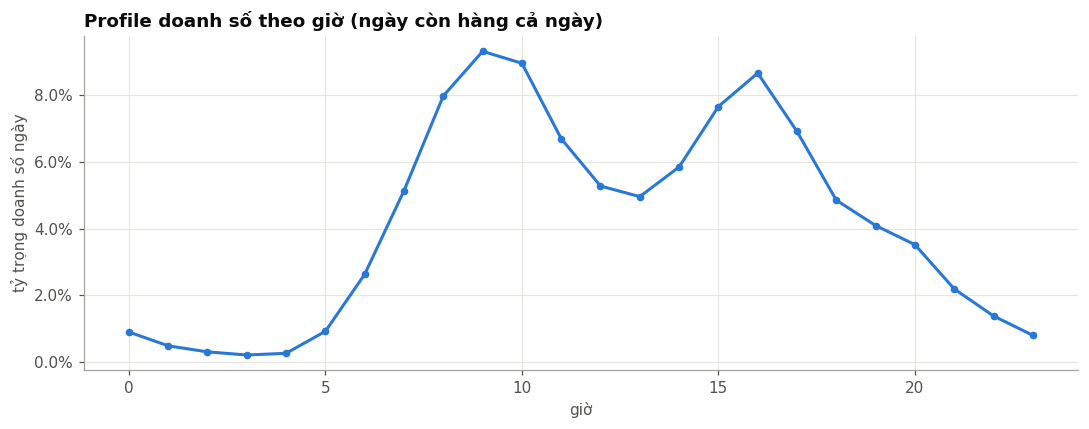

In [5]:
# Quy ước của hours_stock_status: lấy từ notebook 01 nếu có, nếu không thì tự xác định
summ_path = OUT_DIR / "tables" / "eda_summary.json"
STOCKOUT_IS_1 = None
if summ_path.exists():
    STOCKOUT_IS_1 = json.load(open(summ_path, encoding="utf-8")).get("hourly", {}).get("hours_stock_status_1_means_stockout")

tr = ds["train"]
idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(len(tr), size=min(PROFILE_SAMPLE, len(tr)), replace=False))
smp = tr.select(idx).select_columns(["first_category_id", "stock_hour6_22_cnt", "hours_sale", "hours_stock_status"]).to_pandas()
L = int(pd.Series([len(x) for x in smp.hours_sale]).mode()[0])
smp = smp[[len(a) == L and len(b) == L for a, b in zip(smp.hours_sale, smp.hours_stock_status)]]
H = np.stack(smp.hours_sale.values).astype("float64")
S = np.stack(smp.hours_stock_status.values).astype("float64")
if STOCKOUT_IS_1 is None:
    STOCKOUT_IS_1 = bool(np.corrcoef(S[:, 6:22].sum(1), smp.stock_hour6_22_cnt)[0, 1] > 0)
OUTS = S if STOCKOUT_IS_1 else 1 - S
print(f"{L} giờ/ngày; hours_stock_status = 1 nghĩa là {'HẾT' if STOCKOUT_IS_1 else 'CÒN'} hàng")

# Profile: tỷ trọng doanh số theo giờ, chỉ từ ngày còn hàng cả ngày
full = (OUTS.sum(1) == 0) & (H.sum(1) > 0)
global_prof = H[full].sum(0) / H[full].sum()
max_cat = int(max(smp.first_category_id.max(), df.first_category_id.max())) + 1
PROF = np.tile(global_prof, (max_cat, 1))
n_cat_prof = 0
for cat, idxs in pd.Series(np.arange(len(smp))).groupby(smp.first_category_id.values):
    m = full[idxs.values]
    if m.sum() >= 200:  # đủ mẫu thì dùng profile riêng của ngành
        h = H[idxs.values][m]
        PROF[int(cat)] = h.sum(0) / h.sum()
        n_cat_prof += 1
print(f"Profile riêng cho {n_cat_prof} ngành; các ngành còn lại dùng profile chung")

fig, ax = plt.subplots()
ax.plot(global_prof, color=C1, marker="o", markersize=4)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Profile doanh số theo giờ (ngày còn hàng cả ngày)"); ax.set_xlabel("giờ"); ax.set_ylabel("tỷ trọng doanh số ngày")
save(fig, "prep_hourly_profile")

In [6]:
def avail_fn(batch):
    S = np.asarray(batch["hours_stock_status"], dtype="float32")
    instock = (1 - S) if STOCKOUT_IS_1 else S
    cat = np.clip(np.asarray(batch["first_category_id"], dtype="int64"), 0, max_cat - 1)
    return {"avail_share": (PROF[cat] * instock).sum(1).astype("float32")}

parts = []
for split in ds.keys():
    sub = ds[split].select_columns(["store_id", "product_id", "dt", "first_category_id", "hours_stock_status"])
    sub = sub.map(avail_fn, batched=True, batch_size=20_000,
                  remove_columns=["first_category_id", "hours_stock_status"], desc=f"avail_share {split}")
    parts.append(sub.to_pandas())
av = pd.concat(parts, ignore_index=True)
av["dt"] = pd.to_datetime(av["dt"])
av[["store_id", "product_id"]] = av[["store_id", "product_id"]].astype("int32")

df = df.merge(av, on=["store_id", "product_id", "dt"], how="left", validate="one_to_one")
df.loc[df.stock_hour6_22_cnt == 0, "avail_share"] = 1.0  # không hết hàng giờ nào → đủ cầu
df["avail_share"] = df.avail_share.fillna(1.0).clip(0, 1).astype("float32")
print(f"Thiếu avail_share sau khi ghép: {av.avail_share.isna().sum()} | TB avail_share ngày có hết hàng: "
      f"{df.loc[df.stock_hour6_22_cnt > 0, 'avail_share'].mean():.3f}")

avail_share train:   0%|          | 0/4500000 [00:00<?, ? examples/s]

avail_share eval:   0%|          | 0/350000 [00:00<?, ? examples/s]

Thiếu avail_share sau khi ghép: 0 | TB avail_share ngày có hết hàng: 0.589


## 3. Target `y`

- `sales_rec` = `sale_amount` / max(`avail_share`, `MIN_AVAIL`): cầu ước lượng, dùng để tạo các biến trễ.
- `y` = `sales_rec` nếu `avail_share` ≥ `MIN_AVAIL`; ngày **hết hàng nặng** (`avail_share` < 0,5) để trống, không dùng làm target vì hệ số khôi phục quá lớn sẽ khuếch đại nhiễu.

share_rows_recovered                 0.4403
share_rows_heavy_stockout_excluded   0.1511
total_uplift_from_recovery           0.2040
mean_avail_share_on_stockout_days    0.5895


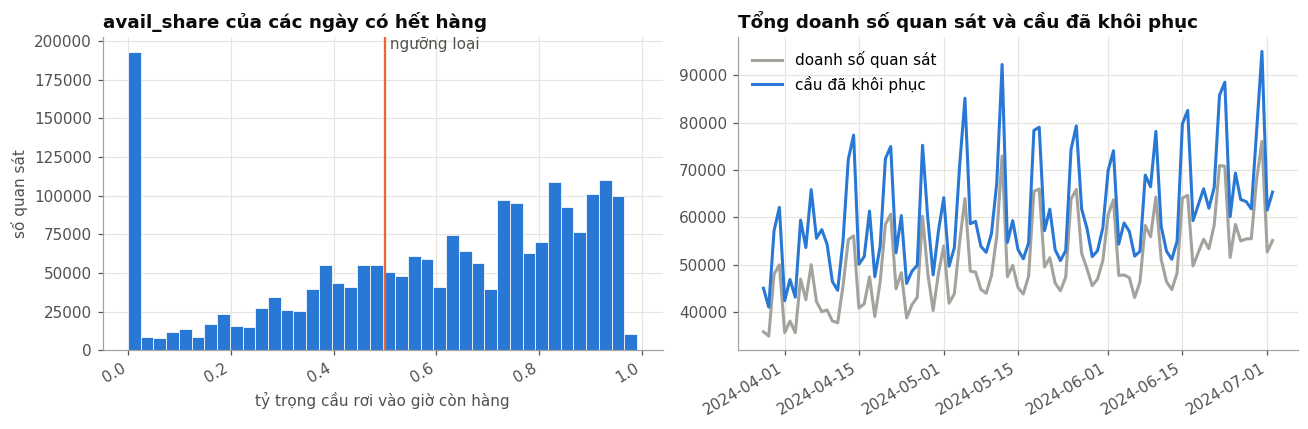

In [7]:
df["sales_rec"] = (df.sale_amount / df.avail_share.clip(lower=MIN_AVAIL)).astype("float32")
df["heavy_stockout"] = (df.avail_share < MIN_AVAIL).astype("int8")
df["y"] = df.sales_rec.where(df.heavy_stockout == 0)

aff = df.avail_share < 0.999
LOG["censoring"] = {
    "share_rows_recovered": float(aff.mean()),
    "share_rows_heavy_stockout_excluded": float(df.heavy_stockout.mean()),
    "total_uplift_from_recovery": float(df.sales_rec.sum() / df.sale_amount.sum() - 1),
    "mean_avail_share_on_stockout_days": float(df.loc[aff, "avail_share"].mean()) if aff.any() else 1.0,
}
print(pd.Series(LOG["censoring"]).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.loc[aff, "avail_share"], bins=40, color=C1, edgecolor="white", linewidth=0.5)
ax[0].axvline(MIN_AVAIL, color=C2, lw=1.5)
ax[0].text(MIN_AVAIL, ax[0].get_ylim()[1], " ngưỡng loại", color=INK2, va="top")
ax[0].set_title("avail_share của các ngày có hết hàng"); ax[0].set_xlabel("tỷ trọng cầu rơi vào giờ còn hàng")
ax[0].set_ylabel("số quan sát")
daily = df.groupby("dt")[["sale_amount", "sales_rec"]].sum()
ax[1].plot(daily.index, daily.sale_amount, color=MUTED, label="doanh số quan sát")
ax[1].plot(daily.index, daily.sales_rec, color=C1, label="cầu đã khôi phục")
ax[1].set_title("Tổng doanh số quan sát và cầu đã khôi phục"); ax[1].legend()
fig.autofmt_xdate()
save(fig, "prep_censoring_recovery")

## 4. Feature engineering

Mọi biến lịch sử chỉ dùng dữ liệu **đến hôm trước** (shift 1 trong từng chuỗi) để tránh rò rỉ. Discount, khuyến mãi, ngày lễ và thời tiết của **ngày cần dự báo** được dùng vì chúng biết trước khi ra quyết định giá (thời tiết lấy từ dự báo).

In [8]:
df = df.sort_values(["series_id", "dt"], ignore_index=True)
gs = df.groupby("series_id", sort=False)

# Historical demand (trên cầu đã khôi phục)
df["sales_lag_1"] = gs.sales_rec.shift(1)
df["sales_lag_7"] = gs.sales_rec.shift(7)
prev = gs.sales_rec.shift(1)
df["rolling_mean_7"] = prev.groupby(df.series_id).rolling(7, min_periods=7).mean().reset_index(level=0, drop=True)
df["rolling_std_7"] = prev.groupby(df.series_id).rolling(7, min_periods=7).std().reset_index(level=0, drop=True)

# Price
df["discount_lag_1"] = gs.discount.shift(1)
is_disc = (df.discount < 0.995).astype("int16")
streak_id = (is_disc != is_disc.groupby(df.series_id).shift(1)).cumsum()
df["disc_streak"] = (is_disc.groupby([df.series_id, streak_id]).cumsum() * is_disc).astype("int16")  # số ngày giảm giá liên tiếp tính đến hôm nay

# Time
df["day_of_week"] = df.dt.dt.dayofweek.astype("int8")

# Stockout hôm trước
df["stockout_hours_lag_1"] = gs.stock_hour6_22_cnt.shift(1)

for c in ["sales_lag_1", "sales_lag_7", "rolling_mean_7", "rolling_std_7", "discount_lag_1", "stockout_hours_lag_1"]:
    df[c] = df[c].astype("float32")

NUM_FEATURES = ["discount", "discount_lag_1", "disc_streak", "sales_lag_1", "sales_lag_7", "rolling_mean_7",
                "rolling_std_7", "day_of_week", "activity_flag", "holiday_flag", "stockout_hours_lag_1",
                "avg_temperature", "precpt"]
CAT_FEATURES = ["first_category_id", "second_category_id", "product_id", "store_id"]
FEATURES = NUM_FEATURES + CAT_FEATURES
# Ràng buộc đơn điệu cho LightGBM: discount tăng (giảm giá ít đi) thì cầu không tăng
MONOTONE = [-1 if f == "discount" else 0 for f in FEATURES]

feat_tbl = pd.DataFrame({"feature": FEATURES,
                         "nhóm": ["Price", "Price", "Price", "Historical demand", "Historical demand", "Demand trend",
                                  "Demand trend", "Time", "Promotion", "Holiday", "Stockout", "Weather", "Weather",
                                  "Category", "Category", "Product", "Store"],
                         "monotone": MONOTONE,
                         "missing_share": [float(df[f].isna().mean()) for f in FEATURES]})
feat_tbl.to_csv(OUT_DIR / "tables" / "table_3_4_features.csv", index=False)
feat_tbl

,feature,nhóm,monotone,missing_share
0,discount,Price,-1,0.0000
1,discount_lag_1,Price,0,0.0103
2,disc_streak,Price,0,0.0000
3,sales_lag_1,Historical demand,0,0.0103
4,sales_lag_7,Historical demand,0,0.0722
5,rolling_mean_7,Demand trend,0,0.0722
6,rolling_std_7,Demand trend,0,0.0722
7,day_of_week,Time,0,0.0000
8,activity_flag,Promotion,0,0.0000
9,holiday_flag,Holiday,0,0.0000


In [9]:
# Kiểm tra rò rỉ: biến trễ của ngày t phải bằng giá trị thật của ngày t-1 trong cùng chuỗi
s0 = df.series_id.iloc[0]
chk = df.loc[df.series_id == s0, ["dt", "sales_rec", "sales_lag_1", "rolling_mean_7"]].head(10).reset_index(drop=True)
assert np.allclose(chk.sales_lag_1.iloc[1:].values, chk.sales_rec.iloc[:-1].values, equal_nan=True)
assert pd.isna(chk.rolling_mean_7.iloc[6]) and np.isclose(chk.rolling_mean_7.iloc[7], chk.sales_rec.iloc[:7].mean())
print("Kiểm tra rò rỉ: đạt (lag_1 = giá trị hôm trước; rolling_mean_7 chỉ dùng 7 ngày trước đó)")
chk

Kiểm tra rò rỉ: đạt (lag_1 = giá trị hôm trước; rolling_mean_7 chỉ dùng 7 ngày trước đó)


,dt,sales_rec,sales_lag_1,rolling_mean_7
0,2024-03-28,1.0000,NaN,NaN
1,2024-03-29,1.5450,1.0000,NaN
2,2024-03-30,5.3000,1.5450,NaN
3,2024-03-31,4.2000,5.3000,NaN
4,2024-04-01,0.7000,4.2000,NaN
5,2024-04-02,2.3000,0.7000,NaN
6,2024-04-03,1.5288,2.3000,NaN
7,2024-04-04,4.7000,1.5288,2.3677
8,2024-04-05,3.1849,4.7000,2.8963
9,2024-04-06,5.8514,3.1849,3.1305


## 5. Chia tập theo thời gian (70 / 15 / 15)

Chia theo ngày, không chia ngẫu nhiên. 7 ngày đầu bị bỏ khỏi tập train vì chưa đủ lịch sử cho `sales_lag_7` và `rolling_mean_7`.

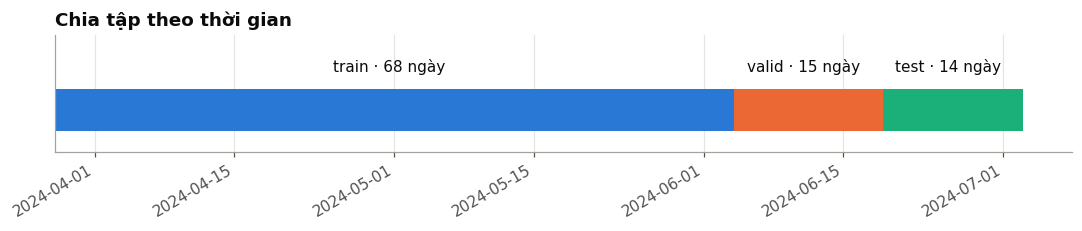

,từ_ngày,đến_ngày,số_ngày,số_dòng,dòng_dùng_được
set,,,,,
train,2024-03-28,2024-06-03,68,3400000,2569465
valid,2024-06-04,2024-06-18,15,750000,642329
test,2024-06-19,2024-07-02,14,700000,602350


In [10]:
days = np.sort(df.dt.unique())
n = len(days)
n_tr, n_va = int(round(SPLIT[0] * n)), int(round(SPLIT[1] * n))
cut_va, cut_te = days[n_tr], days[n_tr + n_va]
df["set"] = np.where(df.dt < cut_va, "train", np.where(df.dt < cut_te, "valid", "test"))
df["usable"] = (df.y.notna() & df.rolling_mean_7.notna() & df.sales_lag_7.notna() & (df.invalid_price == 0)).astype("int8")

split_tbl = (df.groupby("set")
             .agg(từ_ngày=("dt", "min"), đến_ngày=("dt", "max"), số_ngày=("dt", "nunique"),
                  số_dòng=("dt", "size"), dòng_dùng_được=("usable", "sum"))
             .reindex(["train", "valid", "test"]))
split_tbl["từ_ngày"] = split_tbl.từ_ngày.dt.date
split_tbl["đến_ngày"] = split_tbl.đến_ngày.dt.date
split_tbl.to_csv(OUT_DIR / "tables" / "table_3_5_split.csv")
LOG["split"] = {k: {kk: str(vv) for kk, vv in v.items()} for k, v in split_tbl.to_dict("index").items()}

fig, ax = plt.subplots(figsize=(10, 2.2))
colors = {"train": C1, "valid": C2, "test": C3}
for i, s in enumerate(["train", "valid", "test"]):
    r = split_tbl.loc[s]
    ax.barh(0, (pd.Timestamp(r.đến_ngày) - pd.Timestamp(r.từ_ngày)).days + 1, left=pd.Timestamp(r.từ_ngày),
            color=colors[s], height=0.5)
    ax.text(pd.Timestamp(r.từ_ngày) + (pd.Timestamp(r.đến_ngày) - pd.Timestamp(r.từ_ngày)) / 2, 0.42,
            f"{s} · {r.số_ngày} ngày", ha="center", va="bottom", color=INK)
ax.set_yticks([]); ax.set_ylim(-0.5, 0.9); ax.grid(axis="y", visible=False)
ax.set_title("Chia tập theo thời gian")
fig.autofmt_xdate()
save(fig, "prep_time_split")
split_tbl

## 6. Lưu kết quả cho notebook 03

In [11]:
KEEP = (["series_id", "store_id", "product_id", "city_id", "first_category_id", "second_category_id",
         "third_category_id", "dt", "split", "set", "usable", "sale_amount", "sales_rec", "y", "avail_share",
         "heavy_stockout", "stock_hour6_22_cnt", "is_outlier", "invalid_price"] +
        [f for f in NUM_FEATURES if f not in ["discount", "activity_flag", "holiday_flag", "avg_temperature", "precpt"]] +
        ["discount", "activity_flag", "holiday_flag", "avg_temperature", "precpt"])
KEEP = list(dict.fromkeys(KEEP))
df[KEEP].to_parquet(OUT_DIR / "data" / "features.parquet", index=False)

meta = {"target": "y", "features": FEATURES, "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
        "monotone_constraints": MONOTONE, "cut_valid": str(pd.Timestamp(cut_va).date()),
        "cut_test": str(pd.Timestamp(cut_te).date()), "min_avail": MIN_AVAIL,
        "stockout_is_1": STOCKOUT_IS_1, "discount_grid": [1.0, 0.95, 0.9, 0.85, 0.8, 0.75, 0.7],
        "min_valid_discount": MIN_VALID_DISCOUNT}
json.dump(meta, open(OUT_DIR / "data" / "feature_meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
json.dump(LOG, open(OUT_DIR / "tables" / "prep_log.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)

print(f"features.parquet: {len(df):,} dòng × {len(KEEP)} cột; dòng dùng để huấn luyện/đánh giá: {int(df.usable.sum()):,}")
summary = pd.DataFrame([
    ("Ngoại lai được gắn cờ", f"{LOG['anomalies']['outlier_share']:.2%} số dòng (giữ lại)"),
    ("Dòng được khôi phục cầu", f"{LOG['censoring']['share_rows_recovered']:.1%}"),
    ("Dòng hết hàng nặng bị loại khỏi target", f"{LOG['censoring']['share_rows_heavy_stockout_excluded']:.1%}"),
    ("Tổng cầu tăng thêm nhờ khôi phục", f"{LOG['censoring']['total_uplift_from_recovery']:+.1%}"),
    ("Số feature", f"{len(FEATURES)} ({len(NUM_FEATURES)} số, {len(CAT_FEATURES)} phân loại)"),
    ("Mốc chia tập", f"valid từ {meta['cut_valid']}, test từ {meta['cut_test']}"),
], columns=["Bước", "Kết quả"])
summary

features.parquet: 4,850,000 dòng × 32 cột; dòng dùng để huấn luyện/đánh giá: 3,814,144


,Bước,Kết quả
0,Ngoại lai được gắn cờ,0.01% số dòng (giữ lại)
1,Dòng được khôi phục cầu,44.0%
2,Dòng hết hàng nặng bị loại khỏi target,15.1%
3,Tổng cầu tăng thêm nhờ khôi phục,+20.4%
4,Số feature,"17 (13 số, 4 phân loại)"
5,Mốc chia tập,"valid từ 2024-06-04, test từ 2024-06-19"
